# Project 23: Telegram Bot Automated KPI Reporting

Analisis Q1-Q12. Semua tabel dibaca dari `results/` (hasil skrip SQL dan Python). Data adalah simulasi buatan sendiri; pengiriman ke Telegram tidak dilakukan sungguhan (dry-run).

In [1]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd()
while not (ROOT / 'results').exists():
    ROOT = ROOT.parent
R = lambda f: pd.read_csv(next((ROOT / 'results' / d / f) for d in ('1-data-preparation', '2-analysis', '3-presentation') if (ROOT / 'results' / d / f).exists()))
pd.options.display.float_format = '{:.4f}'.format
plt.rcParams.update({'figure.figsize': (9, 3.6), 'axes.spines.top': False, 'axes.spines.right': False})
BLUE, GREY, ORANGE = '#1A73E8', '#9AA0A6', '#E8710A'

## Data bersih
Baris kotor ditemukan dan dipulihkan (`dirty_detection.csv`), lalu pemeriksaan konsistensi.

In [2]:
display(R('dirty_detection.csv')); R('clean_checks.csv')

,kind,ground_truth,detected,true_positive,false_positive,missed,precision,recall
0,duplikat,37,37,37,0,0,1.0000,1.0000
1,ng_negatif,37,37,37,0,0,1.0000,1.0000
2,ok_ng_melebihi_input,37,37,37,0,0,1.0000,1.0000


,check,value,note
0,baris mentah,4477.0000,NaN
1,baris ganda dibuang,37.0000,kunci date-shift-station-model
2,semua ganda identik,1.0000,1 = ya
3,ng negatif dipulihkan,37.0000,ng = input - ok
4,ok+ng melebihi input dipulihkan,37.0000,ok = input - ng
5,baris bersih,4440.0000,NaN
6,persen baris kotor dari mentah,2.4800,target 2-3%
7,ng_qty == jumlah defect_log,1.0000,"1 = ya, semua baris"
8,input stasiun berikut == ok stasiun sebelumnya,1.0000,1 = ya
9,rework date_out >= date_in,1.0000,1 = ya


## Q1. KPI per stasiun (seluruh periode) dan stasiun terburuk

In [3]:
R('kpi_station_period.csv')

,station,seq,input_qty,ng_qty,fpy,ng_rate,rework_rate,scrap_rate,share_of_line_ng,rank_worst_fpy
0,Frame Welding,1,101943.0000,1214.0000,0.9881,0.0119,0.0073,0.0008,0.0969,5
1,Frame Painting,2,100729.0000,3458.0000,0.9657,0.0343,0.0201,0.0024,0.2761,1
2,Engine Assembly,3,97271.0000,1140.0000,0.9883,0.0117,0.0070,0.0009,0.0910,6
3,Wiring Harness Install,4,96131.0000,860.0000,0.9910,0.0089,0.0055,0.0007,0.0687,8
4,Wheel & Suspension,5,95271.0000,931.0000,0.9902,0.0098,0.0059,0.0005,0.0743,7
5,Body Panel Assembly,6,94340.0000,1189.0000,0.9874,0.0126,0.0074,0.0011,0.0949,4
6,Electrical Test,7,93151.0000,1383.0000,0.9851,0.0149,0.0091,0.0010,0.1104,2
7,Final Inspection,8,91768.0000,760.0000,0.9917,0.0083,0.0051,0.0006,0.0607,9
8,Performance Test (Dyno),9,91008.0000,1338.0000,0.9853,0.0147,0.0089,0.0011,0.1068,3
9,Packing,10,89670.0000,253.0000,0.9972,0.0028,0.0017,0.0002,0.0202,10


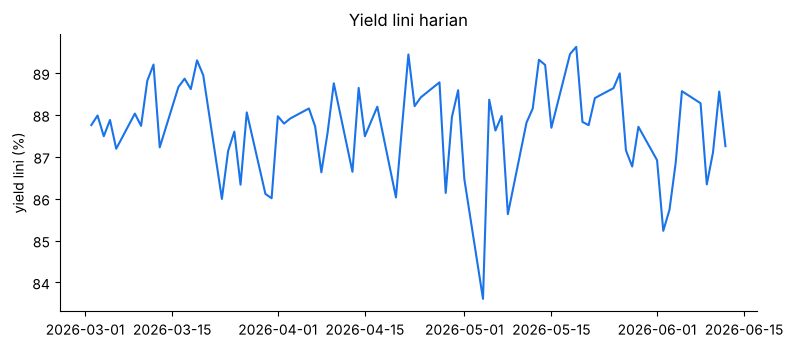

In [4]:
l = R('kpi_line_daily.csv'); plt.plot(pd.to_datetime(l.date), l.line_yield * 100, color=BLUE); plt.ylabel('yield lini (%)'); plt.title('Yield lini harian'); plt.show()

## Q2. Pareto defect (seluruh periode, 7 hari terakhir, hari contoh)

In [5]:
display(R('pareto_period.csv').head(8)); display(R('pareto_latest_7d.csv')); R('pareto_by_day_sample.csv')

,defect_code,defect_name,station,qty,share,cum_share
0,PNT-01,Cat tipis,Frame Painting,1555.0000,0.1241,0.1241
1,PNT-02,Cat berkulit jeruk,Frame Painting,1285.0000,0.1026,0.2267
2,ELT-02,Starter gagal,Electrical Test,780.0000,0.0623,0.2890
3,DYN-01,Akselerasi di bawah spec,Performance Test (Dyno),700.0000,0.0559,0.3449
4,BDY-01,Gores panel body,Body Panel Assembly,655.0000,0.0523,0.3972
5,FWD-01,Porositas las,Frame Welding,644.0000,0.0514,0.4486
6,DYN-02,Rem tidak sesuai tes,Performance Test (Dyno),638.0000,0.0509,0.4995
7,PNT-03,Debu pada cat,Frame Painting,618.0000,0.0493,0.5488


,defect_code,defect_name,station,qty
0,PNT-01,Cat tipis,Frame Painting,143.0000
1,PNT-02,Cat berkulit jeruk,Frame Painting,137.0000
2,DYN-01,Akselerasi di bawah spec,Performance Test (Dyno),83.0000
3,DYN-02,Rem tidak sesuai tes,Performance Test (Dyno),73.0000
4,ELT-02,Starter gagal,Electrical Test,72.0000
5,BDY-01,Gores panel body,Body Panel Assembly,61.0000
6,ELT-01,Lampu tidak menyala,Electrical Test,59.0000
7,FWD-01,Porositas las,Frame Welding,56.0000
8,FIN-01,Cacat kosmetik,Final Inspection,55.0000
9,FWD-02,Dimensi frame meleset,Frame Welding,54.0000


,date,defect_name,station,qty,rnk
0,2026-03-27,Cat tipis,Frame Painting,22.0000,1
1,2026-03-27,Cat berkulit jeruk,Frame Painting,19.0000,2
2,2026-03-27,Celah panel tidak rata,Body Panel Assembly,14.0000,3
3,2026-03-30,Torsi baut kurang,Engine Assembly,30.0000,1
4,2026-03-30,Rembes oli,Engine Assembly,24.0000,2
5,2026-03-30,Cat berkulit jeruk,Frame Painting,17.0000,3
6,2026-05-04,Cat berkulit jeruk,Frame Painting,39.0000,1
7,2026-05-04,Cat tipis,Frame Painting,38.0000,2
8,2026-05-04,Debu pada cat,Frame Painting,14.0000,3
9,2026-06-02,Cat tipis,Frame Painting,32.0000,1


## Q3. 7 hari terakhir vs 7 hari sebelumnya

,date,yield_last7,yield_prev7,delta_pp
55,2026-06-08,0.8705,0.8794,-0.8900
56,2026-06-09,0.8685,0.8792,-1.0700
57,2026-06-10,0.8687,0.8780,-0.9300
58,2026-06-11,0.8735,0.8735,0.0000
59,2026-06-12,0.8757,0.8694,0.6300


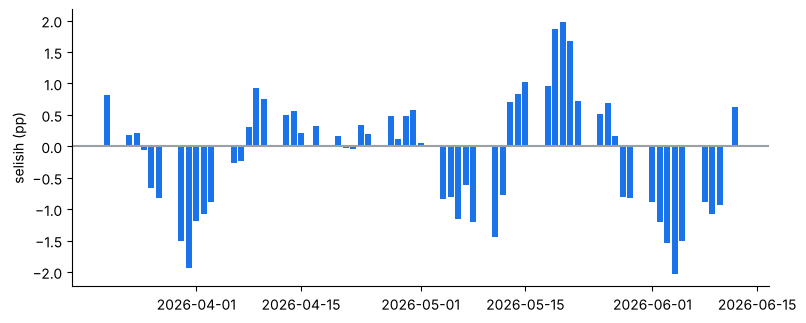

In [6]:
c = R('period_compare_daily.csv'); display(c.tail(5)); plt.bar(pd.to_datetime(c.date), c.delta_pp, color=BLUE); plt.axhline(0, color=GREY); plt.ylabel('selisih (pp)'); plt.show()

## Q4. Ambang yield lini dan stasiun
Kejadian nyata = 3 jendela penurunan yield pada `ground_truth.json`; hari alert di luar jendela = alert palsu.

In [7]:
display(R('alert_eval_line.csv').drop(columns='fp_dates')); R('alert_eval_station.csv').drop(columns='fp_dates')

,rule,param,alert_days,tp_days,fp_days,events_caught,precision_day
0,line_fixed,0.8000,0,0,0,0,NaN
1,line_fixed,0.8200,0,0,0,0,NaN
2,line_fixed,0.8400,1,1,0,1,1.0000
3,line_fixed,0.8500,1,1,0,1,1.0000
4,line_fixed,0.8600,4,3,1,2,0.7500
5,line_fixed,0.8550,2,2,0,2,1.0000
6,line_fixed,0.8650,10,5,5,3,0.5000
7,line_fixed,0.8700,15,8,7,3,0.5330
8,line_rolling_sigma,1.5000,9,5,4,3,0.5560
9,line_rolling_sigma,2.0000,3,3,0,3,1.0000


,rule,param,alert_days,tp_days,fp_days,events_caught,precision_day
0,station_fixed,0.9300,0,0,0,0,0.0000
1,station_fixed,0.9500,2,1,1,1,0.5000
2,station_fixed,0.9600,9,1,8,1,0.1110
3,station_rolling_sigma,2.0000,29,8,21,3,0.2760
4,station_rolling_sigma,2.5000,14,6,8,3,0.4290
5,station_rolling_sigma,3.0000,9,4,5,3,0.4440
6,station_rolling_sigma,3.5000,3,3,0,3,1.0000
7,station_rolling_sigma,4.0000,2,2,0,2,1.0000
8,station_rolling_sigma,5.0000,1,1,0,1,1.0000


## Q6. Aturan lonjakan defect
Termasuk alert palsu di masa pemanasan (`false_alerts_warmup`): aturan window 7 hari tampak bersih bila masa pemanasan dibuang.

In [8]:
R('alert_eval_defect.csv')

,rule,window,param,min_count,alerts,true_alerts,false_alerts,false_alerts_warmup,precision,spike_caught,drops_caught
0,defect_pct,7,0.5000,0,164,17,147,43,0.1040,True,3
1,defect_pct,7,0.5000,5,161,17,144,43,0.1060,True,3
2,defect_pct,7,1.0000,0,45,8,37,12,0.1780,True,2
3,defect_pct,7,1.0000,5,44,8,36,12,0.1820,True,2
4,defect_pct,7,2.0000,0,4,3,1,1,0.7500,True,1
5,defect_pct,7,2.0000,5,4,3,1,1,0.7500,True,1
6,defect_pct,20,0.5000,0,143,19,124,0,0.1330,True,3
7,defect_pct,20,0.5000,5,143,19,124,0,0.1330,True,3
8,defect_pct,20,1.0000,0,39,10,29,0,0.2560,True,3
9,defect_pct,20,1.0000,5,39,10,29,0,0.2560,True,3


## Aturan terpilih: performa pada replay bot dan jeda (Q5)

In [9]:
display(R('alert_rule_performance.csv')); R('alert_lag.csv')

,rule_id,alerts,true_alerts,false_alerts,precision,events_caught,events_total,false_dates
0,R1,3,3,0,1.0000,3,3,NaN
1,R2,3,3,0,1.0000,3,3,NaN
2,R3,12,11,1,0.9170,4,4,2026-04-28


,station,event_start,event_days,first_alert_for,days_to_detect,alert_sent_at,hours_after_shift_end,hours_earlier_than_manual
0,Engine Assembly,2026-03-30,2,2026-03-30,0,2026-03-31 07:01:00,8.0000,5.0000
1,Frame Painting,2026-05-04,1,2026-05-04,0,2026-05-05 07:04:00,8.1000,4.9000
2,Performance Test (Dyno),2026-05-27,7,2026-06-02,4,2026-06-03 08:00:00,9.0000,4.0000


## Q7. Pengiriman tepat waktu

In [10]:
display(R('delivery_summary.csv')); R('day_outcomes.csv').query('not on_time')

,metric,value
0,hari kerja dilaporkan,75.0000
1,pesan daily terkirim,74.0000
2,pesan alert terkirim,8.0000
3,pesan no_data terkirim,4.0000
4,pengiriman gagal (run Actions),3.0000
5,"hari dengan data tiba, laporan terkirim <= 07:15",69.0000
6,hari dengan data tiba,74.0000
7,on-time rate ujung ke ujung (hari dengan data ...,93.2000
8,hari dengan data sudah ada saat run 07:00,72.0000
9,laporan tepat waktu di antara hari tsb,69.0000


,report_date,runner_status,data_arrived,report_sent,sent_at,on_time,alerts,notified_missing,gave_up
15,2026-03-23,success,True,True,2026-03-24 14:00:00,False,0,True,False
22,2026-04-01,failed,True,True,2026-04-02 08:00:00,False,0,False,False
33,2026-04-16,success,False,False,NaN,False,0,True,True
47,2026-05-06,failed,True,True,2026-05-07 08:00:00,False,0,False,False
51,2026-05-12,success,True,True,2026-05-13 13:00:00,False,0,True,False
66,2026-06-02,failed,True,True,2026-06-03 08:00:00,False,2,False,False


## Q8-Q9. Skenario data hilang, perintah, dan pemeriksaan secret

In [11]:
display(R('scenario_tests.csv')[['scenario', 'result']]); display(R('command_tests.csv')[['command', 'result']]); R('secret_scan.csv')

,scenario,result
0,S1 hari normal,lulus
1,S2 hari penurunan yield,lulus
2,S3 data terlambat (tiba siang),lulus
3,S4 data kosong sepanjang hari,lulus
4,S5 run ulang pada hari yang sama,lulus
5,S6 Telegram error 2x lalu berhasil (transport ...,lulus
6,S7 Telegram selalu error (transport palsu),lulus
7,S8 token tidak diset,lulus


,command,result
0,/yield,lulus
1,/top_ng,lulus
2,/trend 7d,lulus
3,/trend 30d,lulus
4,/trend 99d,lulus
5,/trend abc,lulus
6,/help,lulus
7,/yield@kpi_bot,lulus
8,/hapus,lulus


,check,value
0,berkas terlacak yang memuat pola token,0
1,pola token di riwayat git (semua cabang),0
2,workflow memakai secrets.TELEGRAM_BOT_TOKEN,1
3,data mentah dan .duckdb di .gitignore,1


## Q10-Q11. Waktu yang dihemat (waktu manual adalah estimasi)

In [12]:
display(R('impact_time.csv')); R('impact_scenarios.csv')

,item,value,label
0,waktu otomatis per laporan (detik),0.4700,"diukur: median dari 54 laporan, laptop/contain..."
1,waktu otomatis maks (detik),0.6100,diukur
2,waktu manual per laporan (menit),30.0000,ESTIMASI: unduh dan rapikan data 8; hitung yie...
3,waktu baca pesan bot (menit),2.0000,ESTIMASI
4,menit dihemat per laporan,28.0000,estimasi
5,hari kerja per tahun,245.0000,asumsi
6,jam kerja dihemat per tahun,114.3000,estimasi


,manual_minutes_per_report,hours_saved_per_year
0,15,53.1000
1,20,73.5000
2,30,114.3000
3,40,155.2000


## Q12. Cek silang pesan bot vs SQL vs Excel

In [13]:
x = R('crosscheck.csv'); print(f"{int(x[['line_pass','worst_pass','top_pass']].all(axis=1).sum())} dari {len(x)} tanggal lulus semua"); x

12 dari 12 tanggal lulus semua


,date,bot_line,sql_line,excel_line,line_pass,bot_worst,sql_worst,excel_worst,worst_pass,bot_top,sql_top,excel_top_qty,top_pass
0,2026-03-23,0.8600,0.8599,0.8599,True,0.9630,0.9632,0.9632,True,Cat tipis (25),Cat tipis (25),25,True
1,2026-03-30,0.8610,0.8611,0.8611,True,0.9600,0.9600,0.9600,True,Torsi baut kurang (30),Torsi baut kurang (30),30,True
2,2026-03-31,0.8600,0.8601,0.8601,True,0.9630,0.9631,0.9631,True,Torsi baut kurang (25),Torsi baut kurang (25),25,True
3,2026-04-06,0.8820,0.8815,0.8815,True,0.9650,0.9648,0.9648,True,Cat berkulit jeruk (24),Cat berkulit jeruk (24),24,True
4,2026-04-07,0.8770,0.8772,0.8772,True,0.9700,0.9705,0.9705,True,Cat berkulit jeruk (19),Cat berkulit jeruk (19),19,True
5,2026-04-20,0.8600,0.8603,0.8603,True,0.9700,0.9703,0.9703,True,Cat berkulit jeruk (17),Cat berkulit jeruk (17),17,True
6,2026-04-22,0.8940,0.8944,0.8944,True,0.9760,0.9763,0.9763,True,Cat tipis (14),Cat tipis (14),14,True
7,2026-04-23,0.8820,0.8821,0.8821,True,0.9620,0.9622,0.9622,True,Cat berkulit jeruk (25),Cat berkulit jeruk (25),25,True
8,2026-04-27,0.8880,0.8878,0.8878,True,0.9620,0.9618,0.9618,True,Cat berkulit jeruk (22),Cat berkulit jeruk (22),22,True
9,2026-04-29,0.8800,0.8795,0.8795,True,0.9610,0.9607,0.9607,True,Cat berkulit jeruk (24),Cat berkulit jeruk (24),24,True
